In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

print("Environment initialized for Baseline (Before Optimization) Evaluation!")

Environment initialized for Baseline (Before Optimization) Evaluation!


In [2]:
DATASET_PATH = 'data/SYNTHETIC_DATASET_100_CLEANED.csv'
df = pd.read_csv(DATASET_PATH)

targets = ['Mtrue', 'TEtrue', 'Sound']
hats = ['Mhat_v01', 'TEhat_v01', 'Soundhat_v01']
names = ['Misalignment (M)', 'Dynamic Transmission Error (STE)', 'Sound Power Level (LW)']
units = ['µm', 'µm', 'dB']

metrics_before = []
for t, h, name, u in zip(targets, hats, names, units):
    r2 = r2_score(df[t], df[h])
    mae = mean_absolute_error(df[t], df[h])
    rmse = root_mean_squared_error(df[t], df[h])
    metrics_before.append({
        'Output Metric': name,
        'Unit': u,
        'Baseline R²': round(r2, 4),
        'Baseline MAE': round(mae, 4),
        'Baseline RMSE': round(rmse, 4),
        'Production Gate (R² >= 0.80)': '❌ FAILED' if r2 < 0.80 else '✅ PASSED'
    })

df_metrics_before = pd.DataFrame(metrics_before)
display(df_metrics_before)


,Output Metric,Unit,Baseline R²,Baseline MAE,Baseline RMSE,Production Gate (R² >= 0.80)
0,Misalignment (M),µm,0.6892,10.2920,13.2016,❌ FAILED
1,Dynamic Transmission Error (STE),µm,0.2935,0.3647,0.4482,❌ FAILED
2,Sound Power Level (LW),dB,0.4514,3.5103,4.2388,❌ FAILED


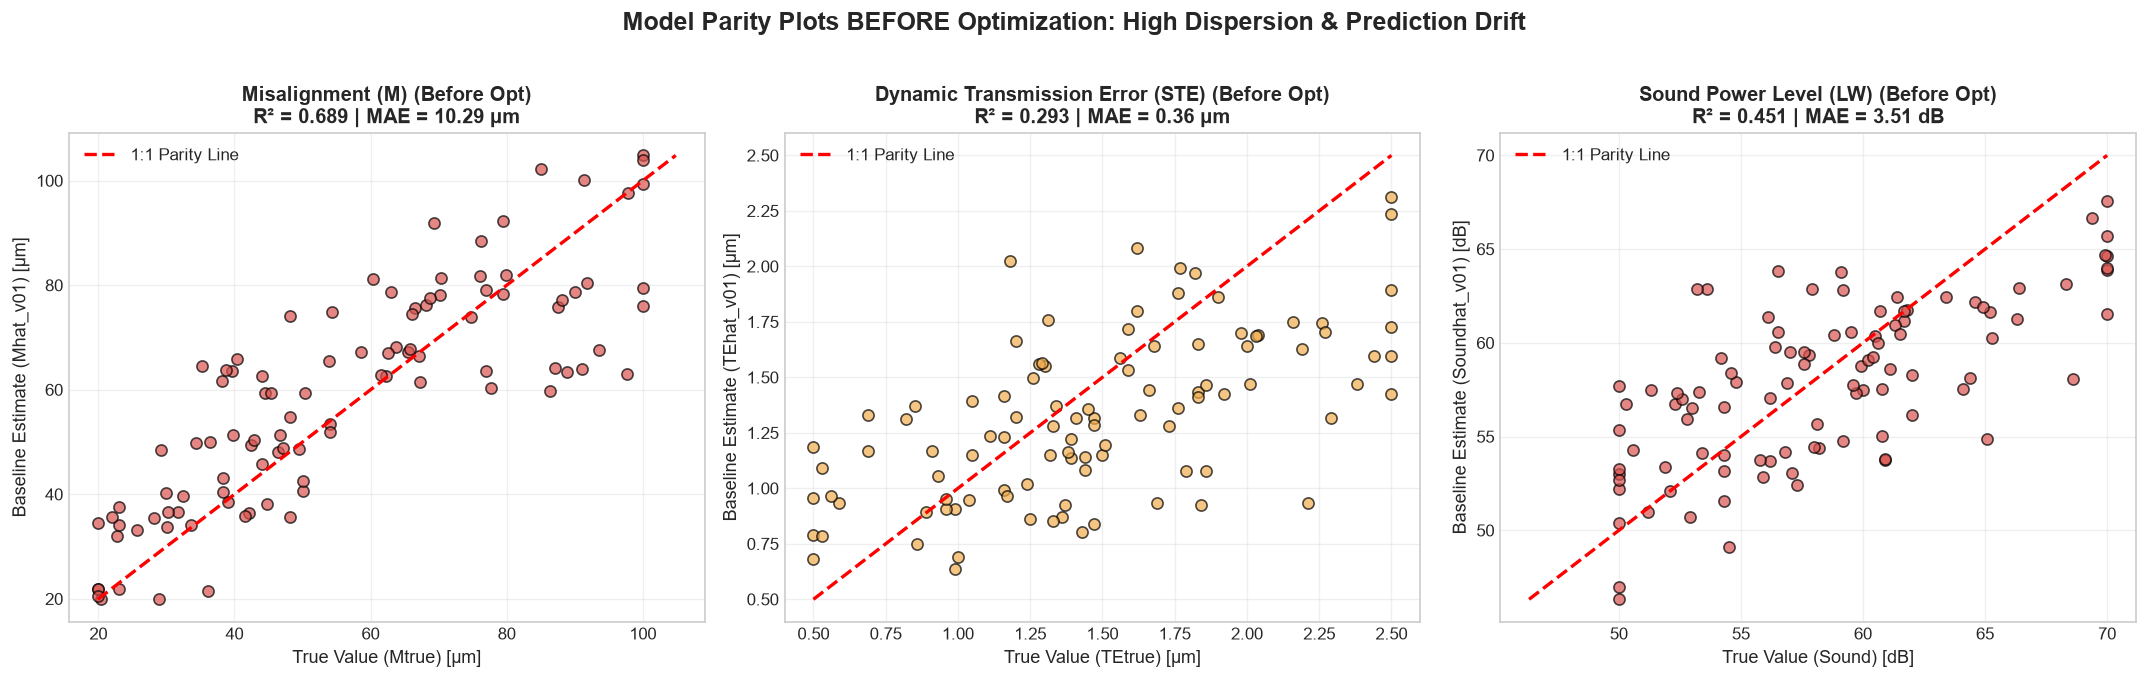

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
colors = ['#d9534f', '#f0ad4e', '#d9534f']

for idx, (t, h, name, u, col) in enumerate(zip(targets, hats, names, units, colors)):
    ax = axes[idx]
    ax.scatter(df[t], df[h], color=col, alpha=0.7, edgecolors='k', s=45)
    min_val = min(df[t].min(), df[h].min())
    max_val = max(df[t].max(), df[h].max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='1:1 Parity Line')
    ax.set_title(f'{name} (Before Opt)\nR² = {df_metrics_before.loc[idx, "Baseline R²"]:.3f} | MAE = {df_metrics_before.loc[idx, "Baseline MAE"]:.2f} {u}', fontsize=12, fontweight='bold')
    ax.set_xlabel(f'True Value ({t}) [{u}]', fontsize=11)
    ax.set_ylabel(f'Baseline Estimate ({h}) [{u}]', fontsize=11)
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)

plt.suptitle('Model Parity Plots BEFORE Optimization: High Dispersion & Prediction Drift', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('plots_before_optimization_parity.png', dpi=200, bbox_inches='tight')
plt.show()


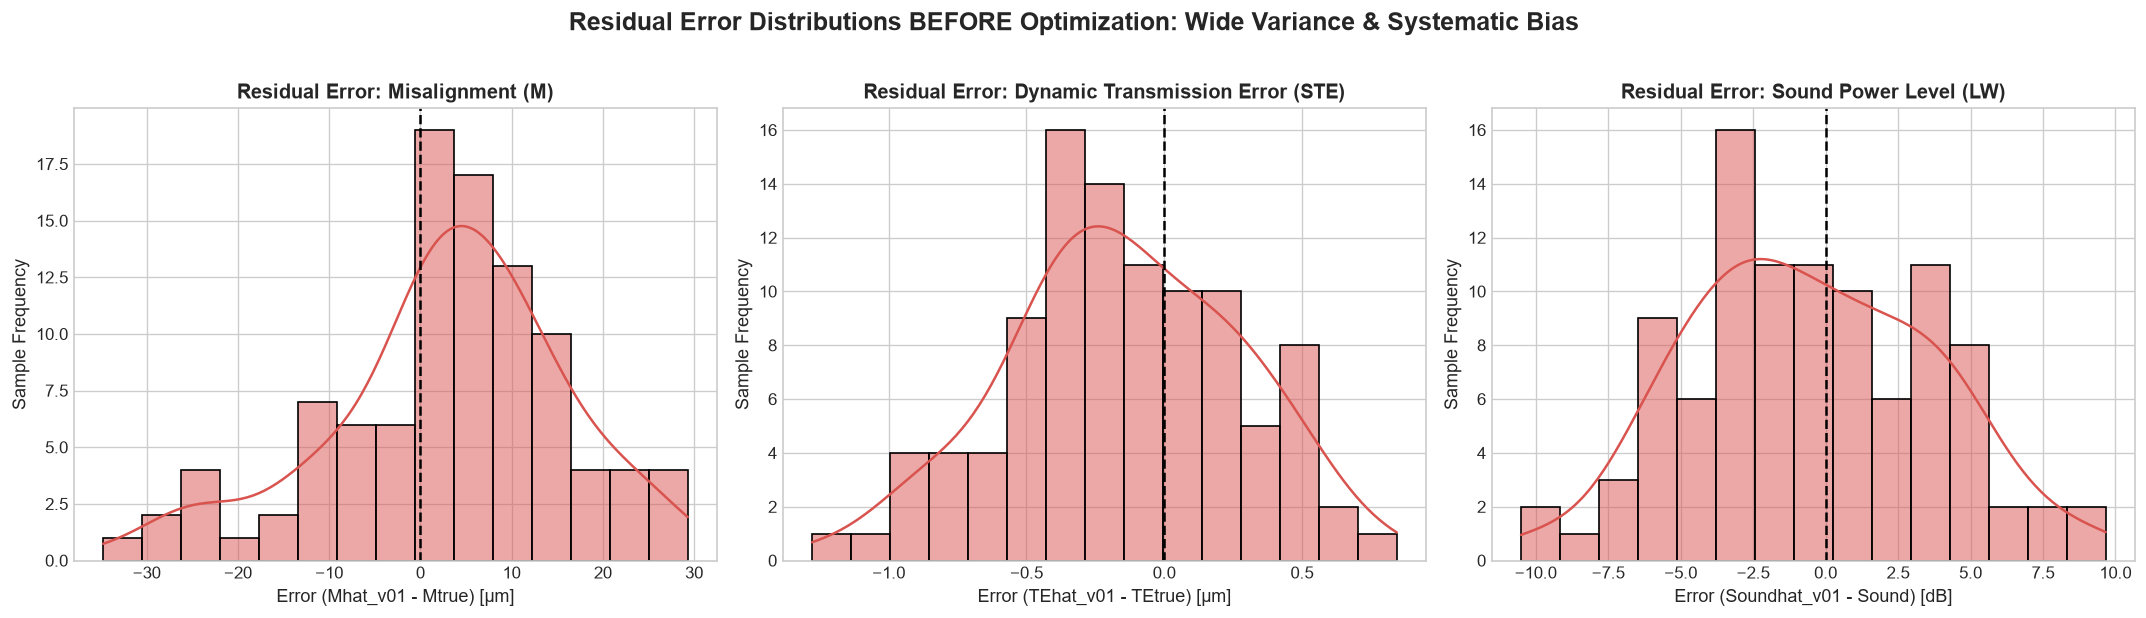

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (t, h, name, u) in enumerate(zip(targets, hats, names, units)):
    residuals = df[h] - df[t]
    ax = axes[idx]
    sns.histplot(residuals, kde=True, ax=ax, color='#d9534f', bins=15, edgecolor='black')
    ax.axvline(0, color='black', linestyle='--', lw=1.5)
    ax.set_title(f'Residual Error: {name}', fontsize=12, fontweight='bold')
    ax.set_xlabel(f'Error ({h} - {t}) [{u}]', fontsize=11)
    ax.set_ylabel('Sample Frequency', fontsize=11)

plt.suptitle('Residual Error Distributions BEFORE Optimization: Wide Variance & Systematic Bias', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('plots_before_optimization_residuals.png', dpi=200, bbox_inches='tight')
plt.show()
